<a href="https://colab.research.google.com/github/mtzwyu/machine-learning/blob/main/Tuan1_Regression/BAI_TAP_VE_NHA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài 1. Thay đổi điều kiện sinh dữ liệu, ví dụ tăng độ nhiễu để kiểm tra độ chính xác của mô

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
np.random.seed(42)
n_samples = 100
x = 2 * np.random.rand(n_samples, 1)
y_true = 4 + 3 * x


noise_levels = {
    "Nhiễu thấp (sigma = 0.5)": 0.5,
    "Nhiễu trung bình (sigma = 1.5)": 1.5,
    "Nhiễu rất cao (sigma = 3.5)": 3.5
}

=== SO SÁNH ĐỘ CHÍNH XÁC CỦA MÔ HÌNH KHI ĐỘ NHIỄU TĂNG ===

[Nhiễu thấp (sigma = 0.5)]
 - Hệ số chặn (Intercept): 4.0715
 - Hệ số góc (Slope)      : 2.8997
 - Mean Squared Error (MSE): 0.1634
 - R^2 score              : 0.9507

[Nhiễu trung bình (sigma = 1.5)]
 - Hệ số chặn (Intercept): 3.8285
 - Hệ số góc (Slope)      : 2.9762
 - Mean Squared Error (MSE): 4.6609
 - R^2 score              : 0.3154

[Nhiễu rất cao (sigma = 3.5)]
 - Hệ số chặn (Intercept): 4.3091
 - Hệ số góc (Slope)      : 3.1127
 - Mean Squared Error (MSE): 4.3699
 - R^2 score              : 0.5280


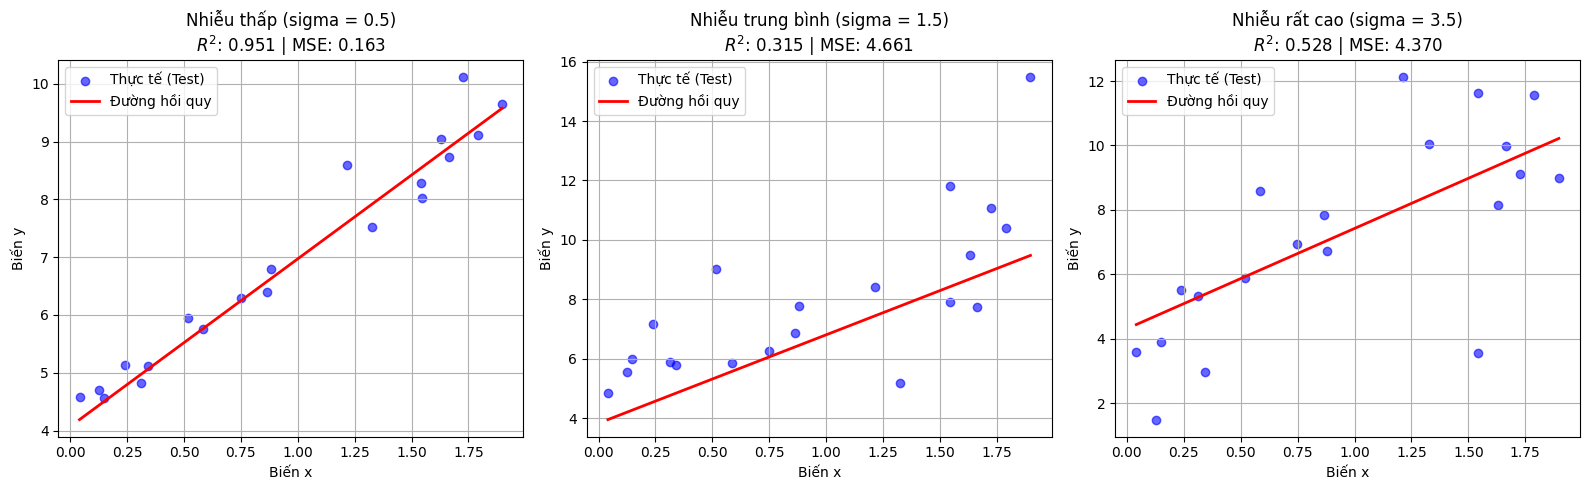

In [4]:
# Chuẩn bị khung biểu đồ
plt.figure(figsize=(16, 5))

print("=== SO SÁNH ĐỘ CHÍNH XÁC CỦA MÔ HÌNH KHI ĐỘ NHIỄU TĂNG ===")

# Duyệt qua từng mức độ nhiễu để huấn luyện và đánh giá
for idx, (label, sigma) in enumerate(noise_levels.items(), 1):
    # Tạo độ nhiễu ngẫu nhiên theo phân phối chuẩn N(0, sigma^2)
    noise = np.random.randn(n_samples, 1) * sigma
    y = y_true + noise

    # Phân chia dữ liệu (80% train, 20% test)
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )

    # Khởi tạo và huấn luyện mô hình
    model = LinearRegression()
    model.fit(x_train, y_train)

    # Dự đoán trên tập kiểm tra
    y_pred = model.predict(x_test)

    # Tính toán độ đo đánh giá
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # In kết quả định lượng
    print(f"\n[{label}]")
    print(f" - Hệ số chặn (Intercept): {model.intercept_[0]:.4f}")
    print(f" - Hệ số góc (Slope)      : {model.coef_[0][0]:.4f}")
    print(f" - Mean Squared Error (MSE): {mse:.4f}")
    print(f" - R^2 score              : {r2:.4f}")

    # Vẽ biểu đồ minh họa
    plt.subplot(1, 3, idx)
    plt.scatter(x_test, y_test, color="blue", alpha=0.6, label="Thực tế (Test)")
    # Sắp xếp lại trục x để đường vẽ không bị đứt gãy
    sorted_idx = np.argsort(x_test[:, 0])
    plt.plot(x_test[sorted_idx], y_pred[sorted_idx], color="red", linewidth=2, label="Đường hồi quy")
    plt.title(f"{label}\n$R^2$: {r2:.3f} | MSE: {mse:.3f}")
    plt.xlabel("Biến x")
    plt.ylabel("Biến y")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# BÀI 2. Đổi ngưỡng dự đoán xác suất (ví dụ 0.6, 0.7,… thay vì 0.5) và quan sát sự thay đổi trong kết quả dự đoán

In [5]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

In [6]:
np.random.seed(42)
n_samples = 400
bmi = np.random.uniform(16, 38, size=(n_samples, 1))

In [7]:
# Xác suất mắc bệnh logic theo hàm Sigmoid quanh mức BMI = 25
prob = 1 / (1 + np.exp(-0.4 * (bmi - 25)))
y = (np.random.rand(n_samples, 1) < prob).astype(int).ravel()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    bmi, y, test_size=0.2, random_state=42
)
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [10]:
y_probs = model.predict_proba(X_test)[:, 1]

In [16]:
#Khảo sát các mức ngưỡng xác suất khác nhau (thay vì cố định 0.5)
thresholds = [0.3, 0.5, 0.6, 0.7, 0.8]


In [17]:
results = []
print(" MA TRẬN NHẦM LẪN VÀ KẾT QUẢ KHI ĐỔI NGƯỠNG ")
for th in thresholds:
    # Gán nhãn 1 nếu xác suất >= threshold, ngược lại là 0
    y_pred_th = (y_probs >= th).astype(int)

    # Tính toán các chỉ số
    acc = accuracy_score(y_test, y_pred_th)
    prec = precision_score(y_test, y_pred_th, zero_division=0)
    rec = recall_score(y_test, y_pred_th, zero_division=0)
    cm = confusion_matrix(y_test, y_pred_th)

    # Ghi nhận kết quả
    results.append({
        "Threshold": th,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "Dự đoán lớp 1 (Bệnh)": int(np.sum(y_pred_th == 1)),
        "Dự đoán lớp 0 (Không)": int(np.sum(y_pred_th == 0))
    })

    print(f"\n--- Ngưỡng dự đoán: {th} ---")
    print(f"Ma trận nhầm lẫn:\n{cm}")

# Hiển thị bảng tổng hợp so sánh
df_results = pd.DataFrame(results)
print("\n BẢNG SO SÁNH HIỆU NĂNG THEO TỪNG NGƯỠNG ")
print(df_results.to_string(index=False))

 MA TRẬN NHẦM LẪN VÀ KẾT QUẢ KHI ĐỔI NGƯỠNG 

--- Ngưỡng dự đoán: 0.3 ---
Ma trận nhầm lẫn:
[[25  9]
 [ 3 43]]

--- Ngưỡng dự đoán: 0.5 ---
Ma trận nhầm lẫn:
[[29  5]
 [ 6 40]]

--- Ngưỡng dự đoán: 0.6 ---
Ma trận nhầm lẫn:
[[30  4]
 [ 7 39]]

--- Ngưỡng dự đoán: 0.7 ---
Ma trận nhầm lẫn:
[[30  4]
 [ 8 38]]

--- Ngưỡng dự đoán: 0.8 ---
Ma trận nhầm lẫn:
[[31  3]
 [ 9 37]]

 BẢNG SO SÁNH HIỆU NĂNG THEO TỪNG NGƯỠNG 
 Threshold  Accuracy  Precision  Recall  Dự đoán lớp 1 (Bệnh)  Dự đoán lớp 0 (Không)
       0.3    0.8500     0.8269  0.9348                    52                     28
       0.5    0.8625     0.8889  0.8696                    45                     35
       0.6    0.8625     0.9070  0.8478                    43                     37
       0.7    0.8500     0.9048  0.8261                    42                     38
       0.8    0.8500     0.9250  0.8043                    40                     40


# Bài 3. Hồi quy tuyến tính với tập dữ liệu giá nhà ở
- Mô tả: Sử dụng thuật toán Linear Regression để dự đoán giá nhà dựa trên một số thuộc tính.
- Yêu cầu:
1. Tải tập dữ liệu Boston Housing từ sklearn.datasets (có thể tải từ kaggle).
2. Phân chia dữ liệu thành tập huấn luyện và tập kiểm tra.
3. Huấn luyện mô hình hồi quy tuyến tính trên tập huấn luyện và dự đoán trên tập kiểm
tra.
4. Tính toán các chỉ số đánh giá: MSE (Mean Squared Error) và R² score cho tập kiểm tra.

In [18]:
# Yêu cầu 1: Tải tập dữ liệu Boston Housing

data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)

In [19]:
# Xử lý định dạng dữ liệu (mỗi mẫu được lưu trên 2 dòng)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

feature_names = [
    'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM',
    'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT'
]

X = data
y = target

print(f"Kích thước tập dữ liệu X: {X.shape}")
print(f"Kích thước nhãn mục tiêu y (Giá nhà - MEDV): {y.shape}")

Kích thước tập dữ liệu X: (506, 13)
Kích thước nhãn mục tiêu y (Giá nhà - MEDV): (506,)


In [20]:
# Yêu cầu 2: Phân chia dữ liệu thành tập huấn luyện và tập kiểm tra

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [21]:
# Yêu cầu 3: Huấn luyện mô hình hồi quy tuyến tính và dự đoán

model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)


In [22]:
# Yêu cầu 4: Tính toán các chỉ số đánh giá MSE và R^2 score


mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST ")
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R^2 score: {r2}")

# Hiển thị mức độ đóng góp (hệ số trọng số) của từng thuộc tính
df_coef = pd.DataFrame({
    'Đặc trưng': feature_names,
    'Hệ số hồi quy (Slope)': model.coef_
}).sort_values(by='Hệ số hồi quy (Slope)', ascending=False)

print("\nBảng hệ số hồi quy của các đặc trưng:")
print(df_coef.to_string(index=False))


 KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST 
Hệ số chặn (Intercept): 30.246750993923776
Mean Squared Error (MSE): 24.291119474973485
R^2 score: 0.6687594935356325

Bảng hệ số hồi quy của các đặc trưng:
Đặc trưng  Hệ số hồi quy (Slope)
       RM               4.438835
     CHAS               2.784438
      RAD               0.262430
    INDUS               0.040381
       ZN               0.030110
        B               0.012351
      AGE              -0.006296
      TAX              -0.010647
     CRIM              -0.113056
    LSTAT              -0.508571
  PTRATIO              -0.915456
      DIS              -1.447865
      NOX             -17.202633


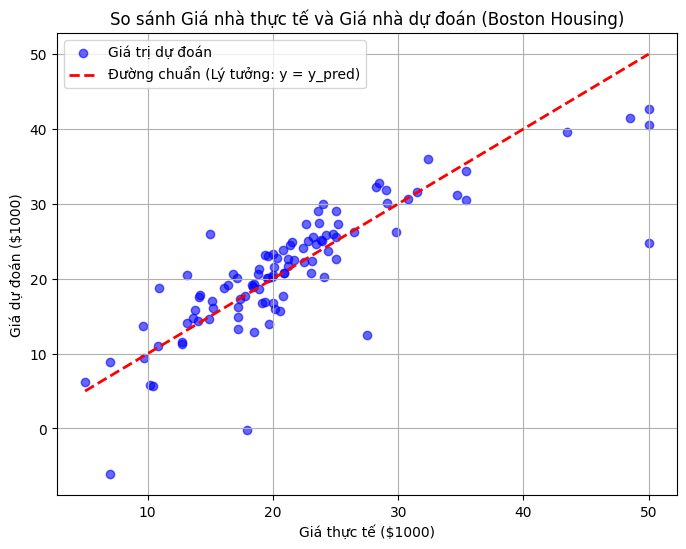

In [23]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Giá trị dự đoán')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Đường chuẩn (Lý tưởng: y = y_pred)')
plt.title("So sánh Giá nhà thực tế và Giá nhà dự đoán (Boston Housing)")
plt.xlabel("Giá thực tế ($1000)")
plt.ylabel("Giá dự đoán ($1000)")
plt.legend()
plt.grid(True)
plt.show()